# Détection du cancer du sein — Classification supervisée

**Auteure :** Ndeye Maimouna Badiane — 4ᵉ année Mathématiques Appliquées et Modélisation, Polytech Lyon
**Langage :** Python (Pandas, Matplotlib, Seaborn, Scikit-learn, XGBoost)

## Objectif

Prédire si une tumeur du sein est **maligne** ou **bénigne** à partir de mesures prises sur des cellules, afin d'aider le médecin à repérer les cas suspects. C'est un problème de **classification binaire** en **apprentissage supervisé** : le modèle apprend sur des patientes dont on connaît le vrai diagnostic, puis prédit celui de nouvelles patientes.

**Critère principal : le rappel.** En médecine, rater un cancer (dire « bénin » à une patiente malade) est bien plus grave qu'une fausse alerte. On cherche donc avant tout à détecter le plus de cancers possible, tout en surveillant l'accuracy.

## Les données

Jeu public **Breast Cancer Wisconsin (Diagnostic)**, téléchargé sur Kaggle (`data.csv`) : **569 patientes**, **30 mesures** des noyaux cellulaires, calculées sur des images de prélèvements par aiguille fine.

Les 30 mesures = **10 caractéristiques** (rayon, texture, périmètre, aire, régularité, compacité, concavité, points concaves, symétrie, dimension fractale) × **3 résumés** : `_mean` (moyenne), `_se` (variabilité) et `_worst` (pire valeur).

## Démarche

| Étape | Contenu |
|---|---|
| 1 | Chargement et nettoyage des données |
| 2 | Analyse exploratoire |
| 3 | Préparation : séparation X / Y, découpage entraînement / test, standardisation |
| 4 | Comparaison de 4 modèles par validation croisée |
| 5 | Optimisation des hyperparamètres (GridSearchCV) |
| 6 | Choix du modèle final |
| 7 | Évaluation finale sur le jeu de test |

## Étape 1 — Chargement et nettoyage des données

### 1.1 Les bibliothèques

**Le code :** importe **Pandas** (manipuler le tableau de données), **Matplotlib** et **Seaborn** (graphiques).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

plt.rcParams["figure.dpi"] = 80

### 1.2 Charger le fichier

**Objectif :** charger `data.csv` dans Colab, où qu'il ait été déposé.

**Le code :** cherche les fichiers CSV présents (`glob`), propose de l'importer s'il n'est pas trouvé, le charge avec `pd.read_csv`, affiche sa taille et ses 5 premières lignes (`head`).

In [2]:
import pandas as pd
import glob

# 1. Chercher tous les fichiers CSV présents dans Colab
fichiers = glob.glob("/*.csv") + glob.glob("/content/**/*.csv", recursive=True)
fichiers = [f for f in fichiers if "sample_data" not in f]
print("Fichiers CSV trouvés :", fichiers)

# 2. Si aucun fichier n'est trouvé, on demande de l'importer
if not fichiers:
    from google.colab import files
    print("Aucun fichier trouvé : choisis data.csv dans ton dossier 'projet cancer du sein'")
    uploaded = files.upload()
    fichiers = list(uploaded.keys())

# 3. Charger le fichier trouvé
df = pd.read_csv(fichiers[0])
print("Fichier chargé :", fichiers[0])
print("Taille du jeu de données :", df.shape)
df.head()

Fichiers CSV trouvés : ['/content/data.csv']
Fichier chargé : /content/data.csv
Taille du jeu de données : (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


**Résultat :** **569 lignes** (une par patiente) et **33 colonnes** : un identifiant (`id`), le diagnostic (`diagnosis` : **M** = maligne, **B** = bénigne), les 30 mesures, et une colonne `Unnamed: 32`.

### 1.3 Rechercher les valeurs manquantes

**Objectif :** un modèle ne sait pas gérer des cases vides ; il faut savoir s'il y en a, et où.

**Le code :** `isnull().sum()` compte les valeurs manquantes de chaque colonne.

In [3]:
import pandas as pd
import glob

# 1. Trouver ou importer le fichier
fichiers = glob.glob("/*.csv") + glob.glob("/content/**/*.csv", recursive=True)
fichiers = [f for f in fichiers if "sample_data" not in f]
if not fichiers:
    from google.colab import files
    print("Choisis data.csv dans ton dossier 'projet cancer du sein'")
    uploaded = files.upload()
    fichiers = list(uploaded.keys())

# 2. Charger le fichier
df = pd.read_csv(fichiers[0])
print("Taille :", df.shape)

# 3. Compter les valeurs manquantes dans chaque colonne
print(df.isnull().sum())

Taille : (569, 33)
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_wo

**Résultat :** **0 valeur manquante** dans toutes les colonnes utiles. Seule la colonne `Unnamed: 32` est **entièrement vide** (569 valeurs manquantes) : c'est une erreur de mise en forme du fichier.

**Ce qu'on retient :** les mesures sont complètes, aucun traitement des valeurs manquantes n'est nécessaire. Il suffit de supprimer la colonne vide.

### 1.4 Supprimer les colonnes inutiles

**Le code :** supprime la colonne vide `Unnamed: 32`, puis la colonne `id`.

**Pourquoi supprimer `id` ?** C'est un simple numéro de dossier : il ne dit rien sur la tumeur. Le garder pourrait pousser le modèle à chercher des liens absurdes entre un numéro et le diagnostic.

In [4]:
df = df.drop(columns=["Unnamed: 32"])

In [5]:
df = df.drop(columns=["id"])


In [6]:
print("Nouvelle taille", df.shape)

Nouvelle taille (569, 31)


**Résultat :** il reste **31 colonnes** : le diagnostic et les 30 mesures.

### 1.5 Encoder le diagnostic

**Objectif :** les modèles ne lisent que des nombres. On remplace **M → 1** (maligne) et **B → 0** (bénigne).

On code **1 = maligne** car c'est la classe qu'on veut **détecter** : c'est elle que mesure le rappel.

In [7]:
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})
df["diagnosis"].head(10)

0    1
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: diagnosis, dtype: int64

## Étape 2 — Analyse exploratoire

### 2.1 Répartition des diagnostics

**Objectif :** savoir combien il y a de cas malins et bénins, et si les deux classes sont équilibrées.

**Le code :** compte chaque classe (`value_counts`), en nombre puis en pourcentage (`normalize=True`), puis trace un diagramme en barres.

In [8]:
print(df["diagnosis"].value_counts())

diagnosis
0    357
1    212
Name: count, dtype: int64


In [9]:
print(df["diagnosis"].value_counts(normalize=True)*100)

diagnosis
0    62.741652
1    37.258348
Name: proportion, dtype: float64


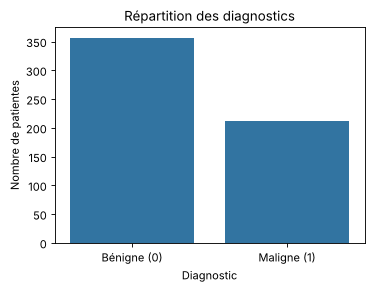

In [10]:
import matplotlib.pyplot as plt
import seaborn as sb

plt.figure(figsize=(5, 3.5))
sb.countplot(x="diagnosis", data=df)
plt.title("Répartition des diagnostics")
plt.xticks([0, 1], ["Bénigne (0)", "Maligne (1)"])
plt.xlabel("Diagnostic")
plt.ylabel("Nombre de patientes")
plt.show()

**Résultats :** **357 bénignes (62,7 %)** et **212 malignes (37,3 %)**.

**Ce qu'on retient :** les classes sont **légèrement déséquilibrées** (moins de cancers). Deux conséquences :
- le découpage entraînement / test devra être **stratifié**, pour garder ces proportions dans chaque groupe ;
- l'**accuracy seule ne suffit pas** : un modèle qui dirait toujours « bénin » aurait déjà 62,7 % de bonnes réponses, tout en ratant 100 % des cancers. D'où le choix du **rappel** comme critère principal.

### 2.2 Statistiques descriptives

**Objectif :** connaître l'ordre de grandeur de chaque mesure.

**Le code :** `describe().T` affiche, pour chaque colonne, le nombre de valeurs (`count`), la moyenne, l'écart-type, le minimum, les quartiles et le maximum (`.T` met une mesure par ligne).

In [11]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
diagnosis,569.0,0.372583,0.483918,0.000000,0.000000,0.000000,1.000000,1.00000
radius_mean,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
texture_mean,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
perimeter_mean,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
area_mean,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
smoothness_mean,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
compactness_mean,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
concavity_mean,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
concave points_mean,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
symmetry_mean,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400


**Ce qu'on retient :** les mesures ont des **échelles très différentes** : l'aire moyenne vaut environ **655** (de 143 à plus de 2 500), alors que la régularité moyenne (`smoothness_mean`) vaut environ **0,1**. Certains modèles (régression logistique, k-NN) seraient dominés par les grandes valeurs : il faudra **standardiser** les données (étape 3).

### 2.3 Corrélations entre les mesures (carte de chaleur)

**Objectif :** voir quelles mesures évoluent ensemble. La **corrélation** varie de −1 à +1 : proche de +1, les deux mesures augmentent ensemble ; proche de 0, pas de lien.

**Le code :** calcule la matrice de corrélation des 30 mesures (le diagnostic est retiré, car c'est la variable à prédire) et l'affiche en carte de chaleur : rouge = forte corrélation positive, bleu = négative.

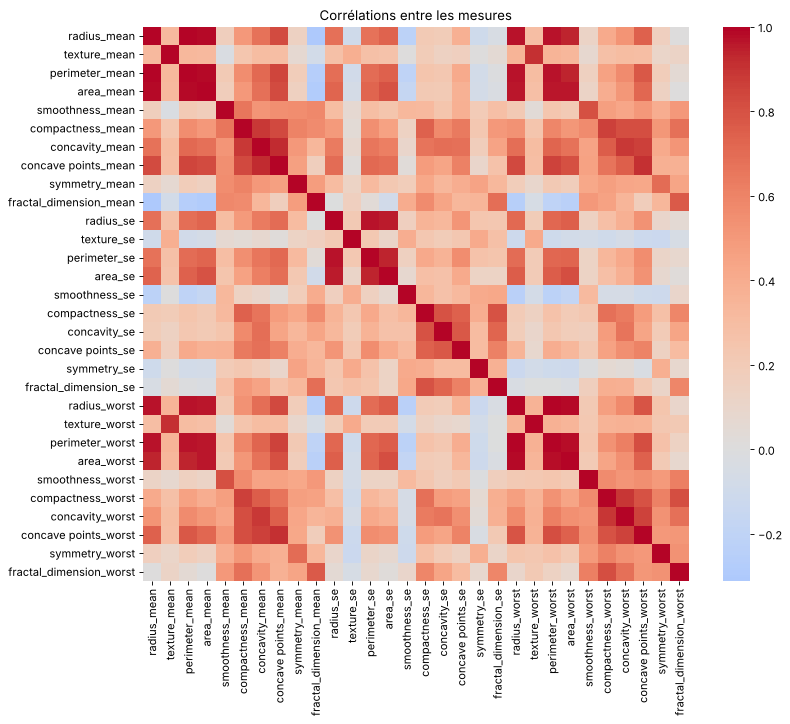

In [12]:
plt.figure(figsize=(11, 9))
sb.heatmap(df.drop(columns=["diagnosis"]).corr(), cmap="coolwarm", center=0)
plt.title("Corrélations entre les mesures")
plt.show()

**Ce qu'on retient :** certaines mesures sont **presque redondantes**, en particulier le **rayon, le périmètre et l'aire**, très fortement corrélés (ce qui est logique : le périmètre et l'aire se calculent à partir du rayon). On parle de **multicolinéarité** : plusieurs variables portent la même information, ce qui est utile à savoir pour interpréter les modèles.

*Rappel : une corrélation ne signifie pas une causalité. Ces mesures accompagnent le cancer, elles ne le provoquent pas.*

### 2.4 Les mesures qui séparent le mieux bénin et malin

**Objectif :** voir, avant tout modèle, si certaines mesures distinguent déjà nettement les deux types de tumeurs. Si c'est le cas, on peut s'attendre à de bons résultats.

**Le code :** pour 4 mesures, trace la distribution des valeurs chez les tumeurs bénignes (bleu) et malignes (rouge). Les 3 premières ont été choisies parmi les plus liées au diagnostic, la 4ᵉ (`smoothness_mean`) pour comparaison.

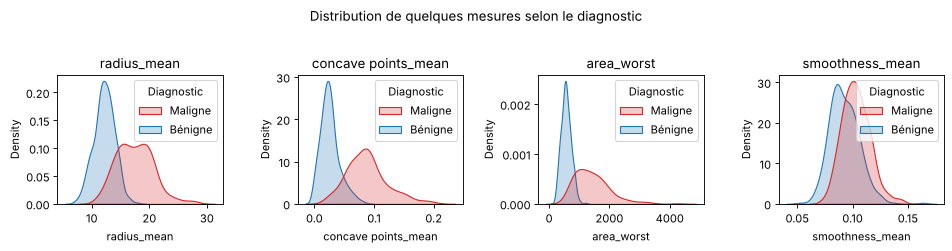

In [13]:
mesures = ["radius_mean", "concave points_mean", "area_worst", "smoothness_mean"]

df_graph = df.assign(Diagnostic=df["diagnosis"].map({0: "Bénigne", 1: "Maligne"}))

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, mesure in zip(axes, mesures):
    sb.kdeplot(data=df_graph, x=mesure, hue="Diagnostic", fill=True, common_norm=False,
               palette={"Bénigne": "tab:blue", "Maligne": "tab:red"}, ax=ax)
    ax.set_title(mesure)
plt.suptitle("Distribution de quelques mesures selon le diagnostic", y=1.03)
plt.tight_layout()
plt.show()

**Ce qu'on retient :**
- Pour `radius_mean`, `concave points_mean` et `area_worst`, les deux courbes sont **bien décalées** : les tumeurs malignes sont en général **plus grandes** et ont **plus de points concaves** (contours irréguliers). Ces mesures sont parmi les plus corrélées au diagnostic (corrélation d'environ 0,73 à 0,78).
- Pour `smoothness_mean`, les courbes se **chevauchent largement** (corrélation d'environ 0,36) : cette mesure, seule, distingue mal les deux classes.
- Les zones de chevauchement montrent qu'**aucune mesure seule ne suffit** : il faut les combiner, c'est le rôle des modèles.

## Étape 3 — Préparation des données

### 3.1 Séparer les mesures (X) et le diagnostic (Y)

- **X** = les 30 mesures : ce que le modèle **regarde** ;
- **Y** = le diagnostic : ce qu'il doit **deviner**.

In [14]:
X = df.drop(columns=["diagnosis"])
Y = df["diagnosis"]
print("taille de X", X.shape)
print("taille de Y", Y.shape)

taille de X (569, 30)
taille de Y (569,)


**Résultat :** X contient 569 lignes et 30 colonnes ; Y contient 569 valeurs. On a retiré une colonne, pas des patientes.

### 3.2 Découper en jeu d'entraînement et jeu de test

**Objectif :** garder une partie des patientes **cachée** jusqu'à la fin, pour évaluer le modèle final sur des cas qu'il n'a jamais vus. Sinon, il pourrait « apprendre par cœur » et obtenir une note trop belle (**fuite de données**).

**Le code :** `train_test_split` garde **80 %** des patientes pour l'entraînement et **20 %** pour le test.
- `stratify=Y` : mêmes proportions de cancers dans les deux groupes ;
- `random_state=42` : fige le hasard, pour que le découpage (et donc les résultats) soit **reproductible**. Le nombre 42 n'a pas de signification particulière.

In [15]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=Y, random_state=42
)

print("Entraînement :", X_train.shape, "| Test :", X_test.shape)
print("Proportion de malignes (entraînement) :", round(Y_train.mean() * 100, 1), "%")
print("Proportion de malignes (test) :", round(Y_test.mean() * 100, 1), "%")

Entraînement : (455, 30) | Test : (114, 30)
Proportion de malignes (entraînement) : 37.4 %
Proportion de malignes (test) : 36.8 %


**Résultats :** **455 patientes d'entraînement** et **114 patientes de test**, avec **37,4 %** et **36,8 %** de cancers : la stratification a bien conservé les proportions.

Le jeu de test ne sera plus utilisé jusqu'à l'évaluation finale (étape 7).

### 3.3 Standardiser les mesures

**Objectif :** mettre toutes les mesures sur la **même échelle**, en ramenant chacune à une **moyenne de 0** et un **écart-type de 1**. Indispensable pour la régression logistique et le k-NN (sensibles à l'échelle) ; sans effet négatif pour les modèles à base d'arbres.

**Le code :** `StandardScaler`
- `fit_transform` sur l'**entraînement** : calcule la moyenne et l'écart-type **uniquement sur ces patientes**, puis transforme ;
- `transform` sur le **test** : applique ces mêmes valeurs, sans rien recalculer, pour ne laisser fuir aucune information du test.

In [16]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Moyenne (entraînement) :", round(X_train_scaled.mean(), 2))
print("Écart-type (entraînement) :", round(X_train_scaled.std(), 2))

Moyenne (entraînement) : 0.0
Écart-type (entraînement) : 1.0


**Résultat :** moyenne **0,0** et écart-type **1,0** sur l'entraînement : la standardisation a bien fonctionné.

## Étape 4 — Comparaison de 4 modèles

### 4.1 Modèle de référence : la régression logistique

**Principe :** le modèle donne un **poids** à chaque mesure, fait la somme pondérée, puis la transforme en **probabilité** entre 0 et 1 grâce à la fonction **sigmoïde**. Au-dessus de 50 %, il prédit « maligne ». Pendant l'apprentissage (`fit`), il ajuste les poids pour faire le moins d'erreurs possible sur l'entraînement.

C'est un modèle **simple et interprétable**, qui sert de **référence** : les modèles plus complexes doivent faire mieux pour mériter leur place.

**Le code :** crée le modèle (`max_iter=1000` : nombre maximum d'itérations pour trouver les poids) et l'entraîne.

In [17]:
from sklearn.linear_model import LogisticRegression

modele = LogisticRegression(max_iter=1000, random_state=42)

modele.fit(X_train_scaled, Y_train)

print("Le modèle est entraîné !")

Le modèle est entraîné !


### 4.2 Évaluation par validation croisée

**Objectif :** noter le modèle de façon fiable **sans toucher au jeu de test**.

**Principe (`StratifiedKFold`, 5 plis) :** les 455 patientes d'entraînement sont coupées en **5 paquets** (chacun avec ≈ 37 % de cancers). Le modèle apprend sur 4 paquets et est noté sur le 5ᵉ ; on recommence 5 fois en changeant de paquet, puis on fait la **moyenne des 5 notes**. La note ne dépend donc pas d'un seul découpage.

**Les deux métriques :**
- **rappel** = parmi les patientes réellement malades, proportion détectée ;
- **accuracy** = proportion de bonnes réponses au total.

In [18]:
from sklearn.model_selection import cross_val_score, StratifiedKFold

decoupage = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rappel = cross_val_score(modele, X_train_scaled, Y_train, cv=decoupage, scoring="recall")
accuracy = cross_val_score(modele, X_train_scaled, Y_train, cv=decoupage, scoring="accuracy")

print("Rappel moyen :", round(rappel.mean() * 100, 1), "%")
print("Accuracy moyenne :", round(accuracy.mean() * 100, 1), "%")

Rappel moyen : 95.3 %
Accuracy moyenne : 97.4 %


**Résultats :** rappel **95,3 %**, accuracy **97,4 %**.

**Ce qu'on retient :** sur environ 170 cancers dans l'entraînement, le modèle en rate environ 8. C'est une **référence solide** pour la suite.

### 4.3 k-NN (k plus proches voisins)

**Principe :** « dis-moi qui tu fréquentes, je te dirai qui tu es ». Pour une nouvelle patiente, le modèle cherche les **k patientes d'entraînement les plus proches** (en distance sur les 30 mesures) et prend le **diagnostic majoritaire** parmi elles. k est un réglage choisi par nous (ici k = 5). Comme il repose sur des distances, la standardisation est indispensable.

In [19]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)

rappel_knn = cross_val_score(knn, X_train_scaled, Y_train, cv=decoupage, scoring="recall")
accuracy_knn = cross_val_score(knn, X_train_scaled, Y_train, cv=decoupage, scoring="accuracy")

print("k-NN - Rappel moyen :", round(rappel_knn.mean() * 100, 1), "%")
print("k-NN - Accuracy moyenne :", round(accuracy_knn.mean() * 100, 1), "%")

k-NN - Rappel moyen : 91.8 %
k-NN - Accuracy moyenne : 96.7 %


**Résultats :** rappel **91,8 %**, accuracy **96,7 %** : moins bon que la régression logistique.

### 4.4 Forêt aléatoire

**Principe :** un **arbre de décision** pose une suite de questions (« le rayon est-il supérieur à 15 ? ») jusqu'à une feuille qui donne le diagnostic. La forêt contient **100 arbres**, chacun entraîné sur un échantillon différent de patientes et de mesures tirées au hasard. Les arbres examinent la même patiente avec des questions différentes, puis **votent** : la majorité l'emporte (**bagging**). Plusieurs arbres différents évitent qu'un seul apprenne par cœur.

In [20]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)

rappel_rf = cross_val_score(rf, X_train_scaled, Y_train, cv=decoupage, scoring="recall")
accuracy_rf = cross_val_score(rf, X_train_scaled, Y_train, cv=decoupage, scoring="accuracy")

print("Random Forest - Rappel moyen :", round(rappel_rf.mean() * 100, 1), "%")
print("Random Forest - Accuracy moyenne :", round(accuracy_rf.mean() * 100, 1), "%")

Random Forest - Rappel moyen : 94.1 %
Random Forest - Accuracy moyenne : 96.5 %


**Résultats :** rappel **94,1 %**, accuracy **96,5 %**.

### 4.5 XGBoost

**Principe :** des arbres construits **les uns après les autres** : chaque nouvel arbre se concentre sur les **erreurs** des précédents, et la prédiction finale additionne leurs contributions (**boosting**). Très performant sur les données en tableau.

In [21]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=100, random_state=42, eval_metric="logloss")

rappel_xgb = cross_val_score(xgb, X_train_scaled, Y_train, cv=decoupage, scoring="recall")
accuracy_xgb = cross_val_score(xgb, X_train_scaled, Y_train, cv=decoupage, scoring="accuracy")

print("XGBoost - Rappel moyen :", round(rappel_xgb.mean() * 100, 1), "%")
print("XGBoost - Accuracy moyenne :", round(accuracy_xgb.mean() * 100, 1), "%")

XGBoost - Rappel moyen : 94.7 %
XGBoost - Accuracy moyenne : 97.1 %


**Résultats :** rappel **94,7 %**, accuracy **97,1 %**.

**Bilan des 4 modèles (réglages par défaut) :**

| Modèle | Rappel | Accuracy |
|---|---|---|
| Régression logistique | **95,3 %** | **97,4 %** |
| XGBoost | 94,7 % | 97,1 % |
| Forêt aléatoire | 94,1 % | 96,5 % |
| k-NN (k = 5) | 91,8 % | 96,7 % |

Avec les réglages de départ, le modèle le plus simple est le meilleur. Reste à savoir si de meilleurs réglages changent le classement.

## Étape 5 — Optimisation des hyperparamètres (GridSearchCV)

**Objectif :** les **hyperparamètres** sont les réglages choisis **avant** l'apprentissage (nombre de voisins, nombre d'arbres…), à distinguer des **paramètres** appris par le modèle (poids, questions des arbres). Les valeurs de départ ont été fixées par défaut : on cherche s'il existe de meilleures valeurs.

**Principe :** GridSearchCV teste **toutes les combinaisons** d'une grille de valeurs, évalue chacune par la **même validation croisée**, et garde celle qui maximise le **rappel**. La valeur de départ fait toujours partie de la grille.

### 5.1 k-NN : nombre de voisins de 1 à 30

In [22]:
from sklearn.model_selection import GridSearchCV

grille = {"n_neighbors": list(range(1, 31))}

recherche = GridSearchCV(KNeighborsClassifier(), grille, cv=decoupage, scoring="recall")
recherche.fit(X_train_scaled, Y_train)

print("Meilleur nombre de voisines :", recherche.best_params_)
print("Meilleur rappel :", round(recherche.best_score_ * 100, 1), "%")

Meilleur nombre de voisines : {'n_neighbors': 1}
Meilleur rappel : 92.9 %


**Résultat :** meilleur k = **1**, rappel **92,9 %** (contre 91,8 % avec k = 5).

**À nuancer :** avec un seul voisin, le modèle copie le diagnostic de la patiente la plus ressemblante. C'est un réglage **fragile**, sensible aux cas atypiques : on vérifiera son accuracy à l'étape 6.

**Visualisation :** le rappel moyen en validation croisée pour chaque valeur de k testée par GridSearchCV (stocké dans `recherche.cv_results_`).

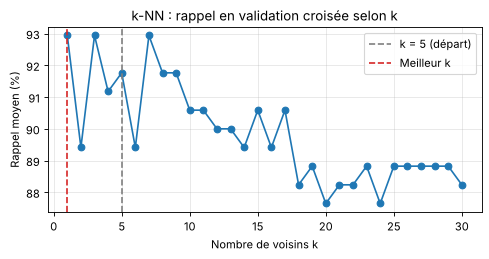

In [23]:
k_testes = grille["n_neighbors"]
rappels_k = recherche.cv_results_["mean_test_score"] * 100

plt.figure(figsize=(7, 3))
plt.plot(k_testes, rappels_k, marker="o")
plt.axvline(5, color="gray", linestyle="--", label="k = 5 (départ)")
plt.axvline(recherche.best_params_["n_neighbors"], color="tab:red", linestyle="--", label="Meilleur k")
plt.xlabel("Nombre de voisins k")
plt.ylabel("Rappel moyen (%)")
plt.title("k-NN : rappel en validation croisée selon k")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Ce qu'on retient :**
- Le rappel est le plus haut pour les **petites valeurs de k** et **baisse quand k augmente** : avec beaucoup de voisins, les tumeurs malignes situées près de la frontière sont « noyées » par la majorité bénigne.
- **k = 1, k = 3 et k = 7 sont à égalité** (92,9 %) : GridSearchCV garde simplement la **première** valeur trouvée, k = 1. Un k un peu plus grand (3 ou 7), à rappel égal, serait **plus robuste** face aux cas atypiques.
- La courbe est **en dents de scie** : avec environ 34 cancers par pli de validation, un cancer de plus ou de moins détecté fait varier le rappel d'environ 0,6 point. Les petites différences ne sont donc pas toutes significatives.

### 5.2 Régression logistique : paramètre de régularisation C

**C** règle à quel point le modèle peut « coller » aux données d'entraînement : petit C = modèle prudent et simple ; grand C = modèle qui suit les détails, avec un risque de surapprentissage. Valeur par défaut : C = 1.

In [24]:
grille_lr = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}

recherche_lr = GridSearchCV(LogisticRegression(max_iter=1000, random_state=42),
                            grille_lr, cv=decoupage, scoring="recall")
recherche_lr.fit(X_train_scaled, Y_train)

print("Meilleur C :", recherche_lr.best_params_)
print("Meilleur rappel :", round(recherche_lr.best_score_ * 100, 1), "%")

Meilleur C : {'C': 1}
Meilleur rappel : 95.3 %


**Résultat :** meilleur C = **1**, rappel **95,3 %** : la valeur par défaut était déjà la meilleure. Le réglage est **confirmé**.

### 5.3 Forêt aléatoire : nombre d'arbres et profondeur

- `n_estimators` : nombre d'arbres (100, 200, 300) ;
- `max_depth` : nombre **maximum** de questions à la suite par arbre (sans limite, 5, 10).

Soit 3 × 3 = 9 combinaisons.

In [25]:
grille_rf = {"n_estimators": [100, 200, 300],
             "max_depth": [None, 5, 10]}

recherche_rf = GridSearchCV(RandomForestClassifier(random_state=42),
                            grille_rf, cv=decoupage, scoring="recall")
recherche_rf.fit(X_train_scaled, Y_train)

print("Meilleurs réglages :", recherche_rf.best_params_)
print("Meilleur rappel :", round(recherche_rf.best_score_ * 100, 1), "%")

Meilleurs réglages : {'max_depth': 5, 'n_estimators': 100}
Meilleur rappel : 94.7 %


**Résultat :** **100 arbres, 5 questions maximum**, rappel **94,7 %** (contre 94,1 %).

**Ce qu'on retient :** limiter la profondeur donne des arbres plus simples, qui apprennent moins par cœur et généralisent mieux.

### 5.4 XGBoost : nombre d'arbres, profondeur et vitesse d'apprentissage

- `n_estimators` : nombre d'arbres, donc de corrections successives (100, 200) ;
- `max_depth` : profondeur des arbres (3, 6) ;
- `learning_rate` : part de sa correction que chaque arbre applique (0,05 ; 0,1 ; 0,3). Petit = corrections prudentes, mais plus d'arbres nécessaires.

Soit 2 × 2 × 3 = 12 combinaisons.

In [26]:
grille_xgb = {"n_estimators": [100, 200],
              "max_depth": [3, 6],
              "learning_rate": [0.05, 0.1, 0.3]}

recherche_xgb = GridSearchCV(XGBClassifier(random_state=42, eval_metric="logloss"),
                             grille_xgb, cv=decoupage, scoring="recall")
recherche_xgb.fit(X_train_scaled, Y_train)

print("Meilleurs réglages :", recherche_xgb.best_params_)
print("Meilleur rappel :", round(recherche_xgb.best_score_ * 100, 1), "%")

Meilleurs réglages : {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200}
Meilleur rappel : 95.9 %


**Résultat :** **200 arbres, profondeur 6, learning rate 0,1**, rappel **95,9 %** (contre 94,7 %).

**Ce qu'on retient :** des corrections plus petites, compensées par davantage d'arbres, améliorent la détection : c'est le meilleur rappel obtenu jusqu'ici.

## Étape 6 — Choix du modèle final

**Objectif :** comparer les 4 modèles **avec leurs meilleurs réglages**, sur le rappel **et** l'accuracy, toujours par validation croisée sur l'entraînement. On choisit **un seul** modèle **avant** de toucher au jeu de test : tester les 4 sur le test et garder le meilleur reviendrait à choisir en regardant les réponses de l'examen.

**Critères, fixés à l'avance :** 1) le rappel ; 2) l'accuracy ; 3) la simplicité.

**Le code :** définit les 4 modèles réglés, puis calcule pour chacun le rappel et l'accuracy moyens en validation croisée.

In [27]:
modeles = {
    "Régression logistique": LogisticRegression(C=1, max_iter=1000, random_state=42),
    "k-NN": KNeighborsClassifier(n_neighbors=1),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                             random_state=42, eval_metric="logloss")
}

resultats = {}

for nom, m in modeles.items():
    rappel = cross_val_score(m, X_train_scaled, Y_train, cv=decoupage, scoring="recall").mean()
    acc = cross_val_score(m, X_train_scaled, Y_train, cv=decoupage, scoring="accuracy").mean()
    resultats[nom] = {"Rappel": rappel * 100, "Accuracy": acc * 100}
    print(nom, ": rappel", round(rappel * 100, 1), "% | accuracy", round(acc * 100, 1), "%")

Régression logistique : rappel 95.3 % | accuracy 97.4 %
k-NN : rappel 92.9 % | accuracy 95.8 %


Forêt aléatoire : rappel 94.7 % | accuracy 96.7 %


XGBoost : rappel 95.9 % | accuracy 97.4 %


**Résultats :**

| Modèle réglé | Rappel | Accuracy |
|---|---|---|
| **XGBoost** | **95,9 %** | **97,4 %** |
| Régression logistique | 95,3 % | 97,4 % |
| Forêt aléatoire | 94,7 % | 96,7 % |
| k-NN (k = 1) | 92,9 % | 95,8 % |

**Ce qu'on retient :**
- **XGBoost** a le meilleur rappel, à accuracy égale avec la régression logistique : il est **retenu**.
- L'écart avec la régression logistique est **faible** (environ 1 cancer sur 170), et celle-ci est plus **interprétable** pour un médecin : en contexte médical, ce compromis se discute.
- Le k-NN réglé (k = 1) gagne en rappel mais **perd en accuracy** (95,8 % contre 96,7 % avec k = 5) : regarder plusieurs métriques évite de retenir un réglage fragile.

**Visualisation :** le rappel et l'accuracy des 4 modèles réglés, côte à côte.

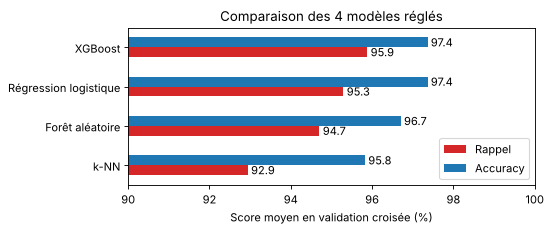

In [28]:
import pandas as pd

tableau = pd.DataFrame(resultats).T.sort_values("Rappel")
ax = tableau.plot.barh(figsize=(7, 3), color=["tab:red", "tab:blue"])
ax.set_xlim(90, 100)
ax.set_xlabel("Score moyen en validation croisée (%)")
ax.set_title("Comparaison des 4 modèles réglés")
for conteneur in ax.containers:
    ax.bar_label(conteneur, fmt="%.1f", padding=3)
plt.tight_layout()
plt.show()

**Ce qu'on retient :** XGBoost et la régression logistique sont **en tête et très proches** (même accuracy, 0,6 point d'écart en rappel). Le k-NN est nettement derrière sur les deux métriques. L'axe commence à 90 % : tous les modèles sont bons, et les écarts restent de quelques points.

## Étape 7 — Évaluation finale sur le jeu de test

**Objectif :** l'examen final, passé **une seule fois**. XGBoost, avec ses réglages optimisés, est entraîné sur les 455 patientes d'entraînement, puis prédit le diagnostic des **114 patientes de test**, jamais vues. On compare ses prédictions aux vrais diagnostics.

**Le code :** entraîne le modèle final, prédit (`predict`), puis calcule le rappel, l'accuracy et la **matrice de confusion** (lignes = vrai diagnostic, colonnes = prédiction).

In [29]:
from sklearn.metrics import recall_score, accuracy_score, confusion_matrix

modele_final = XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                             random_state=42, eval_metric="logloss")
modele_final.fit(X_train_scaled, Y_train)

Y_pred = modele_final.predict(X_test_scaled)

print("Rappel :", round(recall_score(Y_test, Y_pred) * 100, 1), "%")
print("Accuracy :", round(accuracy_score(Y_test, Y_pred) * 100, 1), "%")
print(confusion_matrix(Y_test, Y_pred))

Rappel : 92.9 %
Accuracy : 97.4 %
[[72  0]
 [ 3 39]]


**Résultats :**

| 114 patientes de test | Prédit bénin | Prédit malin |
|---|---|---|
| **Vraiment bénin (72)** | **72** bonnes réponses | **0** fausse alerte |
| **Vraiment malin (42)** | **3** cancers ratés | **39** cancers détectés |

- **Accuracy = 111 / 114 = 97,4 %**
- **Rappel = 39 / 42 = 92,9 %**

**Ce qu'on retient :**
- **Aucune fausse alerte** : aucune patiente saine n'est inquiétée inutilement.
- **3 cancers ratés** : c'est la seule erreur du modèle, et la plus grave.
- Le rappel est plus bas qu'en validation croisée (92,9 % contre 95,9 %) : avec seulement 42 cancers dans le test, chaque cas pèse environ 2,4 points ; l'écart correspond à **une seule patiente**.
- Le modèle est **trop prudent avant de dire « maligne »** (0 fausse alerte, mais 3 cancers ratés).

### 7.1 Matrice de confusion en image

La même matrice que ci-dessus, en couleurs : plus la case est foncée, plus elle contient de patientes.

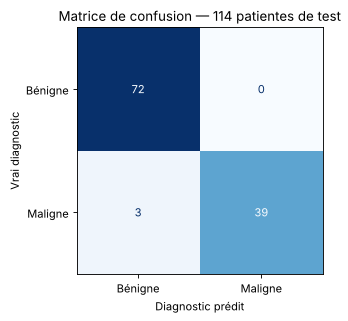

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    Y_test, Y_pred, display_labels=["Bénigne", "Maligne"], cmap="Blues", colorbar=False
)
plt.gcf().set_size_inches(4, 4)
plt.title("Matrice de confusion — 114 patientes de test")
plt.xlabel("Diagnostic prédit")
plt.ylabel("Vrai diagnostic")
plt.show()

**Ce qu'on retient :** les 72 tumeurs bénignes sont toutes bien reconnues (case en haut à droite à 0 : aucune fausse alerte). Les seules erreurs sont les **3 cancers classés bénins** (case en bas à gauche), l'erreur la plus grave en médecine.

### 7.2 Courbe ROC

**Objectif :** le modèle ne donne pas seulement « bénin » ou « malin », il donne une **probabilité** de malignité. Par défaut, on dit « malin » au-dessus de 50 %, mais on pourrait choisir un autre **seuil**.

La **courbe ROC** montre, pour tous les seuils possibles, le compromis entre :
- le **taux de vrais positifs** (= le rappel : cancers détectés) ;
- le **taux de faux positifs** (patientes saines signalées à tort).

Plus la courbe monte vite vers le coin en haut à gauche, meilleur est le modèle. L'**AUC** (aire sous la courbe) résume cela en un nombre : 1 = parfait, 0,5 = hasard.

AUC sur le test : 0.994


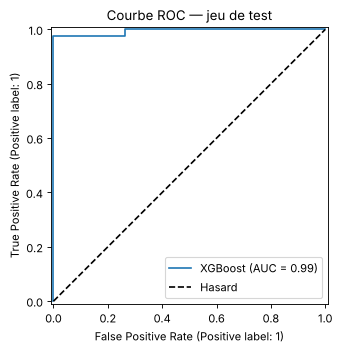

In [31]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score

probas_test = modele_final.predict_proba(X_test_scaled)[:, 1]
print("AUC sur le test :", round(roc_auc_score(Y_test, probas_test), 3))

fig, ax = plt.subplots(figsize=(4.5, 4.5))
RocCurveDisplay.from_predictions(Y_test, probas_test, name="XGBoost", ax=ax)
plt.plot([0, 1], [0, 1], "k--", label="Hasard")
plt.title("Courbe ROC — jeu de test")
plt.legend()
plt.show()

**Résultat :** **AUC = 0,994**, très proche de 1 : le modèle classe presque toujours une tumeur maligne avec une probabilité plus élevée qu'une tumeur bénigne.

**Ce qu'on retient :**
- La courbe monte presque à la verticale : un seuil plus bas permettrait de détecter **plus de cancers** sans créer beaucoup de fausses alertes. Sur ce test, 2 des 3 cancers manqués avaient une probabilité de malignité de 17 % et 30 %, juste sous le seuil de 50 %.
- **Attention :** ce seuil ne doit **pas être choisi en regardant le jeu de test**, sinon on retombe dans la fuite de données. Il faudrait le fixer en validation croisée sur l'entraînement, puis le vérifier une seule fois sur le test. C'est la première piste d'amélioration de ce projet.

### 7.3 Les mesures les plus utilisées par le modèle

**Objectif :** comprendre **sur quoi** le modèle s'appuie pour décider, plutôt que de le traiter comme une boîte noire.

**Le code :** `feature_importances_` donne, pour chaque mesure, sa part dans les décisions des arbres de XGBoost. On affiche les 10 plus importantes.

perimeter_worst         29.799999
concave points_mean     19.700001
radius_worst            18.500000
concave points_worst     9.800000
concavity_worst          2.400000
radius_se                2.100000
texture_mean             2.000000
area_mean                1.900000
area_worst               1.800000
texture_worst            1.600000
dtype: float32


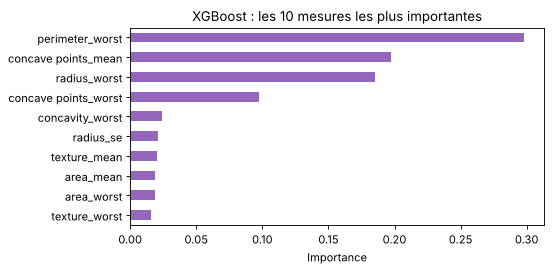

In [32]:
importances = pd.Series(modele_final.feature_importances_, index=X.columns)
top10 = importances.sort_values(ascending=False).head(10)
print((top10 * 100).round(1))

top10.sort_values().plot.barh(figsize=(7, 3.5), color="tab:purple")
plt.xlabel("Importance")
plt.title("XGBoost : les 10 mesures les plus importantes")
plt.tight_layout()
plt.show()

**Ce qu'on retient :**
- Quatre mesures font l'essentiel du travail (environ **78 %** de l'importance à elles quatre) : le **périmètre** et le **rayon** de la tumeur (`perimeter_worst`, `radius_worst`) et le **nombre de points concaves** du contour (`concave points_mean`, `concave points_worst`).
- C'est **cohérent** avec l'exploration (étape 2.4) : les tumeurs malignes sont plus grandes et plus irrégulières.
- **À nuancer :** rayon, périmètre et aire sont fortement corrélés (étape 2.3). Quand plusieurs mesures portent la même information, le modèle en privilégie une et les autres paraissent moins importantes. L'importance indique sur quoi **ce modèle** s'appuie, pas une cause médicale.

## Conclusion

- Après nettoyage (colonne vide et identifiant supprimés) et analyse exploratoire, les données ont été découpées (80 / 20, stratifié) et standardisées sur le seul jeu d'entraînement.
- Quatre modèles ont été comparés par **validation croisée stratifiée à 5 plis**, en privilégiant le **rappel**, puis optimisés avec **GridSearchCV**.
- **XGBoost** (200 arbres, profondeur 6, learning rate 0,1) a été retenu. Sur **114 patientes jamais vues**, il obtient **97,4 % d'accuracy** et **92,9 % de rappel**, avec **aucune fausse alerte** et **3 cancers manqués sur 42**. Son **AUC de 0,994** montre qu'il sépare très bien les deux classes.
- Le modèle s'appuie surtout sur la **taille** de la tumeur et l'**irrégularité de son contour**, ce qui est cohérent avec l'analyse exploratoire.

## Limites et pistes d'amélioration

- **Abaisser le seuil de décision** (50 % par défaut) pour signaler davantage de cas suspects : on détecterait plus de cancers en acceptant quelques fausses alertes, un bon compromis en médecine. Ce seuil doit être choisi sur l'entraînement (validation croisée), jamais en regardant le test.
- **Interprétabilité :** XGBoost est moins lisible que la régression logistique ; on pourrait analyser l'**importance des variables** pour expliquer ses décisions à un médecin.
- **Taille des données :** 569 patientes seulement, et un test de 114 cas ; les résultats devraient être confirmés sur d'autres données.
- Le modèle est un **outil d'aide à la décision** : il ne remplace pas le diagnostic du médecin.